# Revenue Quality & Customer Concentration — A SQL Investigation
## Is growth repeatable, or vulnerable to cancellations and a few large customers?

A sales total is a starting point, not a management conclusion. This project traces a UK retailer's recorded transactions into a reconciled sales bridge, monthly growth drivers, customer concentration, repeat purchasing, and a product investigation list.

**Business question:** Is recorded sales growth supported by repeat purchasing and a broad customer base, or weakened by cancellations and concentration?

**SQL owns the analysis.** Python loads the Excel source, executes the numbered SQL files, and displays tables and figures. No machine-learning model is needed to answer this question. DuckDB runs locally without a server.

Source: [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail), Chen (2015), DOI [10.24432/C5BW33](https://doi.org/10.24432/C5BW33), CC BY 4.0. Amounts are GBP. The analysis calls the financial measure **net recorded sales value**, not accounting revenue, profit, or cash collected.

In [1]:
from pathlib import Path
import sys,json
import duckdb,pandas as pd,numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd()
sys.path.insert(0,str(ROOT/'src'))
from run_pipeline import run_pipeline,REPORTS
if not (ROOT/'database/revenue_quality.duckdb').exists(): run_pipeline()
con=duckdb.connect(str(ROOT/'database/revenue_quality.duckdb'))
def sql_step(filename):
    text=(ROOT/'sql'/filename).read_text()
    display(Markdown('```sql\n'+text+'\n```'))
    con.execute(text)
def report(name,order=''):
    return con.execute('SELECT * FROM report_'+name+(' ORDER BY '+order if order else '')).df()
def money(value): return f'£{float(value):,.2f}'
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'figure.figsize':(9,4.5)})
display(pd.Series(json.loads((ROOT/'data/manifest.json').read_text()),name='Source provenance'))
display(con.execute('SELECT * FROM raw_lines LIMIT 5').df())

source_url                   https://archive.ics.uci.edu/static/public/352/...
source_page                  https://archive.ics.uci.edu/dataset/352/online...
source_sha256                43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93...
source_rows                                                             541909
first_timestamp                                            2010-12-01 08:26:00
last_timestamp                                             2011-12-09 12:50:00
retrieved_or_verified_utc                     2026-10-13T03:41:41.798418+00:00
duckdb_version                                                           1.5.6
policy                       Preserve exact repeats in primary metrics; exc...
Name: Source provenance, dtype: object

,source_row_id,invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country
0,1,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,2,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,3,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,4,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,5,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


## 1. Preserve the source, type the fields, and define the ledger

The raw table preserves every recorded line and gives it a unique source row ID. SQL casts quantities, timestamps, and prices; monetary values use fixed-point decimals. We flag exact repeated lines rather than silently delete them. A line repeated on an invoice could be a source duplicate or a legitimate repeated item entry.

Eligible positive sales require positive quantity and price and a non-cancellation invoice. Negative-quantity lines with positive price are adjustments. Cancellation invoices begin with C. Invalid required fields, negative prices, zero values, and positive-quantity cancellation anomalies are excluded from the primary metric but remain auditable.

Unknown customer IDs remain in financial totals. Country is a transaction attribute; it is not assumed to be a permanent customer attribute. Product descriptions can change, so the dimension keeps one latest description per code. Dimensions are tested for uniqueness before joins.

The fact table is invoice-line grain. Invoice, customer, and product dimensions let the reader see where joins belong; order counts use distinct positive-sale invoice numbers, not line counts.

In [2]:
sql_step('01_prepare.sql')
sql_step('02_quality.sql')
quality=report('quality'); display(quality)
display(report('invoice_integrity'))
repeat=report('repeat_sensitivity');display(repeat)
counts=con.execute("SELECT count(*) AS rows,count(*) FILTER(WHERE customer_id IS NULL) AS missing_customer_ids,count(*) FILTER(WHERE description IS NULL) AS missing_descriptions,count(*) FILTER(WHERE exact_repeat_number>1) AS exact_repeat_lines FROM stg_lines").df().iloc[0]
display(Markdown(f"**Interpretation:** {int(counts.rows):,} source lines include {int(counts.missing_customer_ids):,} unknown customer IDs, {int(counts.missing_descriptions):,} missing descriptions, and {int(counts.exact_repeat_lines):,} exact repeated lines after the first occurrence. These issues affect the questions we can answer. Financial totals keep unidentified customers; customer analyses cannot assign those sales to a person. The repeat-line sensitivity quantifies the effect of a different deduplication policy without assuming it is correct."))

```sql
-- Preserve raw records. SQL owns typing, flags, scope, and monetary arithmetic.
CREATE OR REPLACE TABLE stg_lines AS
WITH typed AS (
    SELECT source_row_id, trim(invoice_no) AS invoice_no,
           trim(stock_code) AS stock_code, description,
           try_cast(quantity AS INTEGER) AS quantity,
           try_cast(invoice_date AS TIMESTAMP) AS invoice_date,
           try_cast(unit_price AS DECIMAL(18,4)) AS unit_price,
           nullif(trim(customer_id),'') AS customer_id,
           nullif(trim(country),'') AS country
    FROM raw_lines
), flagged AS (
    SELECT *, upper(invoice_no) LIKE 'C%' AS cancellation_invoice,
           regexp_full_match(stock_code,'[0-9]{5}[A-Za-z]?') AS product_like_code,
           row_number() OVER (
               PARTITION BY invoice_no, stock_code, description, quantity,
                            invoice_date, unit_price, customer_id, country
               ORDER BY source_row_id
           ) AS exact_repeat_number,
           cast(quantity * unit_price AS DECIMAL(22,4)) AS signed_value
    FROM typed
)
SELECT *, CASE
    WHEN invoice_date IS NULL OR invoice_no IS NULL OR invoice_no = ''
         OR stock_code IS NULL OR stock_code = '' OR quantity IS NULL
         OR unit_price IS NULL THEN 'invalid_required_field'
    WHEN unit_price < 0 THEN 'negative_price'
    WHEN unit_price = 0 OR quantity = 0 THEN 'zero_value'
    WHEN cancellation_invoice AND quantity > 0 THEN 'cancellation_positive_quantity'
    WHEN quantity < 0 AND cancellation_invoice THEN 'cancellation_adjustment'
    WHEN quantity < 0 THEN 'other_negative_adjustment'
    ELSE 'positive_sale'
END AS line_class
FROM flagged;

CREATE OR REPLACE TABLE dim_customers AS
SELECT DISTINCT customer_id FROM stg_lines WHERE customer_id IS NOT NULL;

CREATE OR REPLACE TABLE dim_products AS
SELECT stock_code,
       arg_max(description, invoice_date) FILTER (WHERE description IS NOT NULL) AS latest_description,
       bool_or(product_like_code) AS product_like_code
FROM stg_lines GROUP BY stock_code;

CREATE OR REPLACE TABLE dim_invoices AS
SELECT invoice_no, min(invoice_date) AS first_line_time,
       count(*) AS line_count, count(DISTINCT customer_id) AS identified_customer_count,
       count(DISTINCT country) AS country_count,
       count(DISTINCT cast(invoice_date AS DATE)) AS date_count
FROM stg_lines GROUP BY invoice_no;

CREATE OR REPLACE TABLE fact_lines AS
SELECT * FROM stg_lines;

CREATE OR REPLACE VIEW eligible_lines AS
SELECT *, CASE WHEN line_class='positive_sale' THEN signed_value ELSE 0 END AS gross_sales,
          CASE WHEN line_class IN ('cancellation_adjustment','other_negative_adjustment')
               THEN -signed_value ELSE 0 END AS negative_adjustment_value
FROM fact_lines
WHERE line_class IN ('positive_sale','cancellation_adjustment','other_negative_adjustment');

CREATE OR REPLACE TABLE dim_months AS
WITH bounds AS (
 SELECT date_trunc('month',min(invoice_date)) AS first_month,
        date_trunc('month',max(invoice_date)) AS final_observed_month
 FROM stg_lines
)
SELECT cast(month AS DATE) AS month,
       month < final_observed_month AS complete_observed_month
FROM bounds, generate_series(first_month,final_observed_month,INTERVAL 1 MONTH) t(month);

```

```sql
-- Do not silently delete exact repeated lines or customers with unknown IDs.
CREATE OR REPLACE VIEW report_quality AS
SELECT line_class, count(*) AS line_count,
       sum(signed_value) AS recorded_signed_value,
       count(*) FILTER (WHERE customer_id IS NULL) AS unidentified_lines,
       count(*) FILTER (WHERE exact_repeat_number > 1) AS exact_repeat_lines,
       count(*) FILTER (WHERE NOT product_like_code) AS non_product_code_lines
FROM stg_lines GROUP BY line_class;

CREATE OR REPLACE VIEW report_invoice_integrity AS
SELECT count(*) AS invoices,
       count(*) FILTER (WHERE identified_customer_count > 1) AS invoices_with_multiple_customer_ids,
       count(*) FILTER (WHERE country_count > 1) AS invoices_with_multiple_countries,
       count(*) FILTER (WHERE date_count > 1) AS invoices_on_multiple_dates
FROM dim_invoices;

CREATE OR REPLACE VIEW report_repeat_sensitivity AS
SELECT 'Preserve all recorded lines (primary)' AS treatment,
       count(*) AS eligible_lines, sum(signed_value) AS net_recorded_sales
FROM eligible_lines
UNION ALL
SELECT 'Keep first exact repeat only (sensitivity)', count(*),sum(signed_value)
FROM eligible_lines WHERE exact_repeat_number=1;

```

,line_class,line_count,recorded_signed_value,unidentified_lines,exact_repeat_lines,non_product_code_lines
0,zero_value,2515,0.000000e+00,2475,5,32
1,positive_sale,530104,1.066668e+07,132220,5226,2762
2,cancellation_adjustment,9288,-8.968125e+05,383,37,589
3,negative_price,2,-2.212412e+04,2,0,2


,invoices,invoices_with_multiple_customer_ids,invoices_with_multiple_countries,invoices_on_multiple_dates
0,25900,0,0,0


,treatment,eligible_lines,net_recorded_sales
0,Preserve all recorded lines (primary),539392,9769872.054
1,Keep first exact repeat only (sensitivity),534129,9748131.074


**Interpretation:** 541,909 source lines include 135,080 unknown customer IDs, 1,454 missing descriptions, and 5,268 exact repeated lines after the first occurrence. These issues affect the questions we can answer. Financial totals keep unidentified customers; customer analyses cannot assign those sales to a person. The repeat-line sensitivity quantifies the effect of a different deduplication policy without assuming it is correct.

## 2. Reconcile sales: how much recorded value remains after adjustments?

Gross positive sales minus eligible negative adjustments equals net recorded sales. We separately bridge back to all typed source values, including excluded negative-price entries. Thus a cleaning decision cannot quietly disappear from the headline metric.

The adjustment-value ratio is adjustment amounts recorded in the period divided by positive sales recorded in the period. It is **not a matched order-return probability**: credit notes are not authoritatively linked to original invoices, and the original sale may precede the observation window. Credit-note values do not demonstrate lost cash or avoidable losses.

Cancellation-prefixed records include administrative fee entries such as AMAZONFEE. This all-eligible-monetary-line ratio is not a merchandise return rate; the product investigation uses a separate code-based scope.

```sql
-- Credit notes cannot be linked to original invoices from these fields alone.
CREATE OR REPLACE VIEW report_reconciliation AS
SELECT sum(gross_sales) AS gross_positive_sales,
       coalesce(sum(negative_adjustment_value) FILTER (WHERE line_class='cancellation_adjustment'),0) AS cancellation_adjustments,
       coalesce(sum(negative_adjustment_value) FILTER (WHERE line_class='other_negative_adjustment'),0) AS other_negative_adjustments,
       sum(negative_adjustment_value) AS total_negative_adjustments,
       sum(signed_value) AS net_recorded_sales,
       sum(negative_adjustment_value)/nullif(sum(gross_sales),0) AS adjustment_value_ratio,
       sum(gross_sales) FILTER (WHERE customer_id IS NULL) / nullif(sum(gross_sales),0) AS unidentified_gross_share,
       sum(signed_value) FILTER (WHERE NOT product_like_code) AS net_non_product_code_value,
       count(DISTINCT invoice_no) FILTER (WHERE line_class='positive_sale') AS positive_sale_invoices,
       count(DISTINCT customer_id) FILTER (WHERE line_class='positive_sale') AS identified_purchasers
FROM eligible_lines;

CREATE OR REPLACE VIEW report_ledger_bridge AS
SELECT sum(signed_value) AS all_typed_recorded_value,
       sum(signed_value) FILTER (WHERE line_class IN ('positive_sale','cancellation_adjustment','other_negative_adjustment')) AS eligible_net_value,
       coalesce(sum(signed_value) FILTER (WHERE line_class NOT IN ('positive_sale','cancellation_adjustment','other_negative_adjustment')),0) AS excluded_typed_value,
       count(*) FILTER (WHERE signed_value IS NULL) AS unvalued_lines
FROM stg_lines;

CREATE OR REPLACE VIEW report_large_adjustments AS
SELECT source_row_id,invoice_no,stock_code,description,customer_id,invoice_date,
       negative_adjustment_value
FROM eligible_lines WHERE negative_adjustment_value>0
ORDER BY negative_adjustment_value DESC,source_row_id LIMIT 20;

```

,gross_positive_sales,cancellation_adjustments,other_negative_adjustments,total_negative_adjustments,net_recorded_sales,adjustment_value_ratio,unidentified_gross_share,net_non_product_code_value,positive_sale_invoices,identified_purchasers
0,1.066668e+07,896812.49,0.0,896812.49,9769872.054,0.084076,0.164557,-6175.156,19960,4338


,all_typed_recorded_value,eligible_net_value,excluded_typed_value,unvalued_lines
0,9747747.934,9769872.054,-22124.12,0


,source_row_id,invoice_no,stock_code,description,customer_id,invoice_date,negative_adjustment_value
0,540423,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",16446,2011-12-09 09:27:00,168469.60
1,61625,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,12346,2011-01-18 10:17:00,77183.60
2,222682,C556445,M,Manual,15098,2011-06-10 15:31:00,38970.00
3,524603,C580605,AMAZONFEE,AMAZON FEE,NaN,2011-12-05 11:36:00,17836.46
4,43703,C540117,AMAZONFEE,AMAZON FEE,NaN,2011-01-05 09:55:00,16888.02


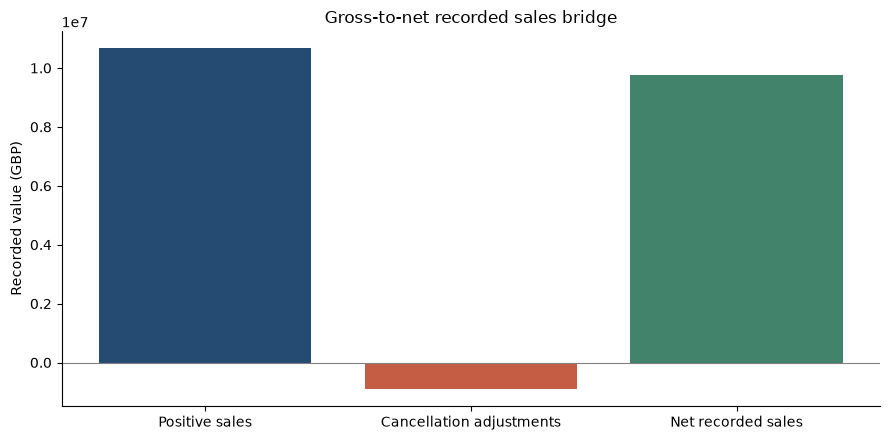

**Interpretation:** £10,666,684.54 in positive sales is offset by £896,812.49, leaving **£9,769,872.05** in eligible net value. Adjustments equal **8.4%** of positive sales. The two largest adjustment lines account for **27.4%** of adjustment value, so investigate large records before attributing the ratio to widespread product problems. **16.5%** of positive value has no customer ID.

In [3]:
sql_step('03_reconcile.sql')
recon=report('reconciliation').iloc[0];display(report('reconciliation'));display(report('ledger_bridge'))
large=report('large_adjustments','negative_adjustment_value DESC');display(large.head(5))
top2_share=float(large.head(2).negative_adjustment_value.sum()/recon.total_negative_adjustments)
fig,ax=plt.subplots()
ax.bar(['Positive sales','Cancellation adjustments','Net recorded sales'],[float(recon.gross_positive_sales),-float(recon.total_negative_adjustments),float(recon.net_recorded_sales)],color=['#264b73','#c55d45','#42836b'])
ax.axhline(0,color='gray',linewidth=.8);ax.set(ylabel='Recorded value (GBP)',title='Gross-to-net recorded sales bridge');fig.tight_layout();fig.savefig(ROOT/'figures/sales_bridge.png',dpi=160);plt.show()
display(Markdown(f"**Interpretation:** {money(recon.gross_positive_sales)} in positive sales is offset by {money(recon.total_negative_adjustments)}, leaving **{money(recon.net_recorded_sales)}** in eligible net value. Adjustments equal **{recon.adjustment_value_ratio:.1%}** of positive sales. The two largest adjustment lines account for **{top2_share:.1%}** of adjustment value, so investigate large records before attributing the ratio to widespread product problems. **{recon.unidentified_gross_share:.1%}** of positive value has no customer ID."))

## 3. Explain monthly growth: volume, invoice value, or adjustments?

SQL groups the line ledger by month, counts distinct positive-sale invoices, and calculates their average positive value. `LAG` compares complete observed months; a window computes a three-month average. The final December 2011 is incomplete and is shown but excluded from comparable growth calculations.

The exact arithmetic bridge is:

**Gross change = (current orders − prior orders) × prior average invoice value + current orders × (current average invoice value − prior average invoice value).**

This convention values the volume change first. It reconciles the change but is not a causal decomposition, price/mix analysis, or proof that a sales intervention worked.

```sql
CREATE OR REPLACE VIEW report_monthly AS
WITH monthly AS (
 SELECT cast(date_trunc('month',invoice_date) AS DATE) AS month,
        sum(gross_sales) AS gross_positive_sales,
        sum(negative_adjustment_value) AS negative_adjustments,
        sum(signed_value) AS net_recorded_sales,
        count(DISTINCT invoice_no) FILTER (WHERE line_class='positive_sale') AS positive_sale_invoices
 FROM eligible_lines GROUP BY 1
)
SELECT d.month,d.complete_observed_month,
       coalesce(m.gross_positive_sales,0) AS gross_positive_sales,
       coalesce(m.negative_adjustments,0) AS negative_adjustments,
       coalesce(m.net_recorded_sales,0) AS net_recorded_sales,
       coalesce(m.positive_sale_invoices,0) AS positive_sale_invoices,
       m.gross_positive_sales/nullif(m.positive_sale_invoices,0) AS average_positive_invoice_value,
       m.negative_adjustments/nullif(m.gross_positive_sales,0) AS adjustment_value_ratio
FROM dim_months d LEFT JOIN monthly m USING(month);

CREATE OR REPLACE VIEW report_growth_bridge AS
WITH lagged AS (
 SELECT *, lag(gross_positive_sales) OVER(ORDER BY month) AS prior_gross,
           lag(positive_sale_invoices) OVER(ORDER BY month) AS prior_orders,
           lag(average_positive_invoice_value) OVER(ORDER BY month) AS prior_aov,
           lag(net_recorded_sales) OVER(ORDER BY month) AS prior_net,
           avg(net_recorded_sales) OVER(ORDER BY month ROWS BETWEEN 2 PRECEDING AND CURRENT ROW) AS rolling_3month_net
 FROM report_monthly WHERE complete_observed_month
)
SELECT *, gross_positive_sales-prior_gross AS gross_change,
       (positive_sale_invoices-prior_orders)*prior_aov AS order_volume_effect,
       positive_sale_invoices*(average_positive_invoice_value-prior_aov) AS invoice_value_effect,
       (net_recorded_sales-prior_net)/nullif(prior_net,0) AS net_monthly_growth
FROM lagged;
-- Sequential decomposition: quantity effect at prior AOV, then AOV at current volume.
-- This is an arithmetic attribution; it does not identify a causal growth driver.

```

,month,complete_observed_month,gross_positive_sales,negative_adjustments,net_recorded_sales,positive_sale_invoices,average_positive_invoice_value,adjustment_value_ratio
0,2010-12-01,True,823746.140,74789.12,748957.020,1559,528.381103,0.090791
1,2011-01-01,True,691364.560,131364.30,560000.260,1086,636.615617,0.190007
2,2011-02-01,True,523631.890,25569.24,498062.650,1100,476.028991,0.048831
3,2011-03-01,True,717639.360,34372.28,683267.080,1454,493.562146,0.047896
4,2011-04-01,True,537808.621,44601.50,493207.121,1246,431.628107,0.082932
5,2011-05-01,True,770536.020,47202.51,723333.510,1681,458.379548,0.061259
6,2011-06-01,True,761739.900,70616.78,691123.120,1533,496.894912,0.092705
7,2011-07-01,True,719221.191,37921.08,681300.111,1475,487.607587,0.052725
8,2011-08-01,True,759138.380,54333.75,704804.630,1361,557.779853,0.071573
9,2011-09-01,True,1058590.172,38902.55,1019687.622,1837,576.260300,0.036749


,month,complete_observed_month,gross_positive_sales,negative_adjustments,net_recorded_sales,positive_sale_invoices,average_positive_invoice_value,adjustment_value_ratio,prior_gross,prior_orders,prior_aov,prior_net,rolling_3month_net,gross_change,order_volume_effect,invoice_value_effect,net_monthly_growth
8,2011-08-01,True,759138.380,54333.75,704804.630,1361,557.779853,0.071573,719221.191,1475,487.607587,681300.111,6.924093e+05,39917.189,-55587.264932,95504.453932,0.034500
9,2011-09-01,True,1058590.172,38902.55,1019687.622,1837,576.260300,0.036749,759138.380,1361,557.779853,704804.630,8.019308e+05,299451.792,265503.210051,33948.581949,0.446766
10,2011-10-01,True,1154979.300,84274.63,1070704.670,2040,566.166324,0.072966,1058590.172,1837,576.260300,1019687.622,9.317323e+05,96389.128,116980.840999,-20591.712999,0.050032
11,2011-11-01,True,1509496.330,47740.08,1461756.250,2769,545.141325,0.031626,1154979.300,2040,566.166324,1070704.670,1.184050e+06,354517.030,412735.249853,-58218.219853,0.365228


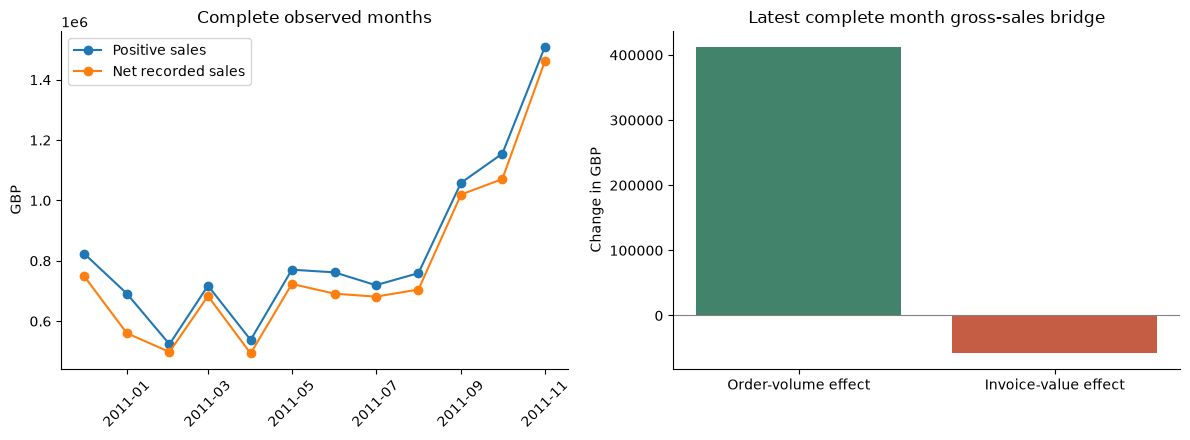

**Interpretation:** in the latest complete month, November 2011, net recorded sales increased **36.5%** over the previous month. Positive sales grew by **£354,517.03**: **£412,735.25** from invoice volume, offset by **£-58,218.22** from lower average positive invoice value. Growth therefore reflects more recorded purchase invoices, rather than higher average invoice value. One annual window cannot separate seasonality from sustained growth.

In [4]:
sql_step('04_monthly.sql')
monthly=report('monthly','month');growth=report('growth_bridge','month')
display(monthly);display(growth.tail(4))
complete=monthly[monthly.complete_observed_month].copy()
latest=growth.iloc[-1]
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].plot(complete.month,complete.gross_positive_sales.astype(float),marker='o',label='Positive sales')
axes[0].plot(complete.month,complete.net_recorded_sales.astype(float),marker='o',label='Net recorded sales')
axes[0].set(title='Complete observed months',ylabel='GBP');axes[0].legend();axes[0].tick_params(axis='x',rotation=45)
axes[1].bar(['Order-volume effect','Invoice-value effect'],[float(latest.order_volume_effect),float(latest.invoice_value_effect)],color=['#42836b','#c55d45'])
axes[1].set(title='Latest complete month gross-sales bridge',ylabel='Change in GBP');axes[1].axhline(0,color='gray',linewidth=.8)
fig.tight_layout();fig.savefig(ROOT/'figures/monthly_growth.png',dpi=160);plt.show()
display(Markdown(f"**Interpretation:** in the latest complete month, {pd.Timestamp(latest.month):%B %Y}, net recorded sales increased **{latest.net_monthly_growth:.1%}** over the previous month. Positive sales grew by **{money(latest.gross_change)}**: **{money(latest.order_volume_effect)}** from invoice volume, offset by **{money(latest.invoice_value_effect)}** from lower average positive invoice value. Growth therefore reflects more recorded purchase invoices, rather than higher average invoice value. One annual window cannot separate seasonality from sustained growth."))

## 4. Measure customer concentration without hiding the missing IDs

Customer totals use identified customers only. `ROW_NUMBER` ranks by positive sales and a cumulative window measures how quickly sales accumulate among the largest accounts. Concentration uses **gross positive sales**, avoiding unstable shares from customers with negative net totals.

The denominator is identified-customer positive sales, not total company sales. SQL also reports customer negative adjustments/net value and country-level totals. Products and customers are not treated as independent evidence of profit.

The gross top-ten table includes customer 12346 with £77,183.60 positive sales and zero net value, and customer 16446 with £168,472.50 positive sales but only £2.90 net. Review gross and net together before interpreting account dependence.

```sql
CREATE OR REPLACE VIEW report_customer_concentration AS
WITH totals AS (
 SELECT customer_id,sum(gross_sales) AS gross_positive_sales,
        sum(negative_adjustment_value) AS negative_adjustments,sum(signed_value) AS net_recorded_sales,
        count(DISTINCT invoice_no) FILTER(WHERE line_class='positive_sale') AS purchase_invoices
 FROM eligible_lines WHERE customer_id IS NOT NULL GROUP BY customer_id
), ranked AS (
 SELECT *,row_number() OVER(ORDER BY gross_positive_sales DESC,customer_id) AS customer_rank,
        gross_positive_sales/sum(gross_positive_sales) OVER() AS identified_gross_share,
        sum(gross_positive_sales) OVER(ORDER BY gross_positive_sales DESC,customer_id ROWS UNBOUNDED PRECEDING)
        /sum(gross_positive_sales) OVER() AS cumulative_identified_gross_share
 FROM totals WHERE gross_positive_sales>0
)
SELECT * FROM ranked;

CREATE OR REPLACE VIEW report_concentration_summary AS
SELECT count(*) AS identified_purchasers,
       sum(identified_gross_share) FILTER(WHERE customer_rank<=10) AS top10_identified_gross_share,
       sum(identified_gross_share) FILTER(WHERE customer_rank<=ceil(identified_purchasers*.01)) AS top1pct_identified_gross_share
FROM report_customer_concentration, (SELECT count(*) AS identified_purchasers FROM report_customer_concentration);

CREATE OR REPLACE VIEW report_customer_country AS
SELECT country,sum(gross_sales) AS gross_positive_sales,
       sum(signed_value) AS net_recorded_sales,
       sum(negative_adjustment_value)/nullif(sum(gross_sales),0) AS adjustment_value_ratio,
       dense_rank() OVER(ORDER BY sum(signed_value) DESC) AS net_sales_rank
FROM eligible_lines GROUP BY country;

```

,customer_id,gross_positive_sales,negative_adjustments,net_recorded_sales,purchase_invoices,customer_rank,identified_gross_share,cumulative_identified_gross_share
0,14646,280206.02,717.00,279489.02,73,1,0.031444,0.031444
1,18102,259657.30,3218.81,256438.49,60,2,0.029138,0.060581
2,17450,194550.79,7068.62,187482.17,46,3,0.021832,0.082413
3,16446,168472.50,168469.60,2.90,2,4,0.018905,0.101318
4,14911,143825.06,11252.44,132572.62,201,5,0.016139,0.117457
5,12415,124914.53,1189.08,123725.45,21,6,0.014017,0.131475
6,14156,117379.63,3995.49,113384.14,55,7,0.013172,0.144647
7,17511,91062.38,2937.00,88125.38,31,8,0.010219,0.154865
8,16029,81024.84,30032.23,50992.61,63,9,0.009092,0.163958
9,12346,77183.60,77183.60,0.00,1,10,0.008661,0.172619


,identified_purchasers,top10_identified_gross_share,top1pct_identified_gross_share
0,4338,0.172619,0.319989


,country,gross_positive_sales,net_recorded_sales,adjustment_value_ratio,net_sales_rank
0,United Kingdom,9025222.084,8209930.484,0.090335,1
1,Netherlands,285446.340,284661.540,0.002749,2
2,EIRE,283453.960,263276.820,0.071183,3
3,Germany,228867.140,221698.210,0.031324,4
4,France,209715.110,197403.900,0.058704,5
5,Australia,138521.310,137077.270,0.010425,6
6,Switzerland,57089.900,56385.350,0.012341,7
7,Spain,61577.110,54774.580,0.110472,8


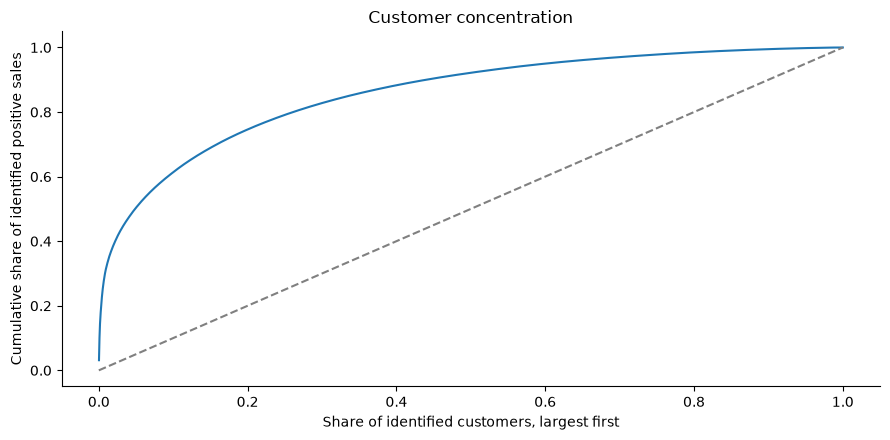

**Interpretation:** the top ten identified purchasers contribute **17.3%** of identified positive sales; the top 1% (rounded up) contribute **32.0%**. This is a reason to monitor large-account exposure and relationships, not proof that those accounts will leave. The 16.5% unidentified-sales share limits conclusions about total-business concentration.

In [5]:
sql_step('05_concentration.sql')
customers=report('customer_concentration','customer_rank'); concentration=report('concentration_summary').iloc[0]
display(customers.head(10));display(report('concentration_summary'));display(report('customer_country','net_sales_rank').head(8))
fig,ax=plt.subplots()
ax.plot(customers.customer_rank/len(customers),customers.cumulative_identified_gross_share)
ax.plot([0,1],[0,1],'--',color='gray');ax.set(xlabel='Share of identified customers, largest first',ylabel='Cumulative share of identified positive sales',title='Customer concentration');fig.tight_layout();fig.savefig(ROOT/'figures/customer_concentration.png',dpi=160);plt.show()
display(Markdown(f"**Interpretation:** the top ten identified purchasers contribute **{concentration.top10_identified_gross_share:.1%}** of identified positive sales; the top 1% (rounded up) contribute **{concentration.top1pct_identified_gross_share:.1%}**. This is a reason to monitor large-account exposure and relationships, not proof that those accounts will leave. The {recon.unidentified_gross_share:.1%} unidentified-sales share limits conclusions about total-business concentration."))

## 5. Test repeat purchasing with cohorts that have time to mature

Each customer enters the month of their **first observed positive purchase**, not necessarily their first-ever purchase. The earliest cohort can contain existing customers because the source window begins in December 2010.

Each customer counts once per activity month. We generate all eligible cohort-month cells before joining activity: an observed month with no repeat purchasers is zero, while a future or partial month is excluded. The denominator is the original cohort size. Weighted cohort summaries include only cohorts old enough to be observed at that age.

Month-one repeat activity and having any second invoice in the whole window are different questions. Rates at different cohort ages involve different eligible cohorts; an upward pattern is not proof that the same customers become more loyal.

```sql
-- Cohorts are first OBSERVED positive purchase; do not claim first-ever acquisition.
-- One customer counts once per month, regardless of invoice count.
CREATE OR REPLACE VIEW report_cohort_retention AS
WITH purchase_months AS (
 SELECT DISTINCT customer_id,cast(date_trunc('month',invoice_date) AS DATE) AS activity_month
 FROM eligible_lines WHERE customer_id IS NOT NULL AND line_class='positive_sale'
), first_purchase AS (
 SELECT customer_id,min(activity_month) AS cohort_month FROM purchase_months GROUP BY customer_id
), sizes AS (
 SELECT cohort_month,count(*) AS cohort_customers FROM first_purchase GROUP BY cohort_month
), observed AS (
 SELECT f.cohort_month,p.activity_month,count(*) AS active_customers
 FROM purchase_months p JOIN first_purchase f USING(customer_id)
 GROUP BY f.cohort_month,p.activity_month
), eligible_periods AS (
 SELECT s.cohort_month,s.cohort_customers,d.month AS activity_month,
        date_diff('month',s.cohort_month,d.month) AS months_since_first_observed_purchase
 FROM sizes s JOIN dim_months d ON d.month>=s.cohort_month AND d.complete_observed_month
)
SELECT e.*,coalesce(o.active_customers,0) AS active_customers,
       coalesce(o.active_customers,0)::DOUBLE/e.cohort_customers AS monthly_repeat_rate
FROM eligible_periods e LEFT JOIN observed o USING(cohort_month,activity_month);

CREATE OR REPLACE VIEW report_cohort_summary AS
SELECT months_since_first_observed_purchase AS month_age,
       count(*) AS eligible_cohorts,sum(cohort_customers) AS eligible_customers,
       sum(active_customers) AS active_customers,
       sum(active_customers)::DOUBLE/sum(cohort_customers) AS weighted_monthly_repeat_rate
FROM report_cohort_retention GROUP BY 1;

CREATE OR REPLACE VIEW report_purchase_frequency AS
WITH purchases AS (
 SELECT customer_id,count(DISTINCT invoice_no) AS positive_purchase_invoices
 FROM eligible_lines WHERE customer_id IS NOT NULL AND line_class='positive_sale' GROUP BY customer_id
)
SELECT count(*) AS identified_purchasers,
       count(*) FILTER(WHERE positive_purchase_invoices>=2) AS purchasers_with_repeat_invoice,
       count(*) FILTER(WHERE positive_purchase_invoices>=2)::DOUBLE/count(*) AS observed_repeat_purchaser_share
FROM purchases;

```

,month_age,eligible_cohorts,eligible_customers,active_customers,weighted_monthly_repeat_rate
0,0,12,4297.0,4297.0,1.000000
1,1,11,3974.0,940.0,0.236537
2,2,10,3616.0,901.0,0.249170
3,3,9,3317.0,893.0,0.269219
4,4,8,3148.0,884.0,0.280813
5,5,7,2960.0,857.0,0.289527
6,6,6,2718.0,781.0,0.287344
7,7,5,2434.0,698.0,0.286771
8,8,4,2134.0,658.0,0.308341
9,9,3,1682.0,602.0,0.357907


,identified_purchasers,purchasers_with_repeat_invoice,observed_repeat_purchaser_share
0,4338,2845,0.655832


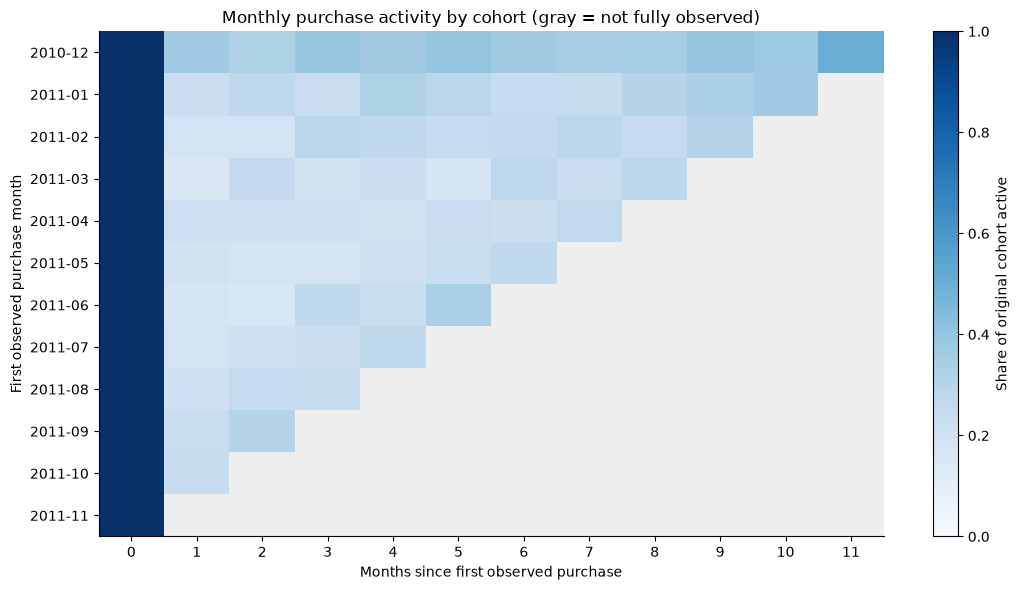

**Interpretation:** among the **3,974** customers in cohorts with a fully observed next month, **23.7%** purchased in that next calendar month. Across the entire source window, **65.6%** of identified purchasers have at least two positive purchase invoices. That supports investigating repeat-purchase patterns, but different observation lengths prevent treating the whole-window rate as a standardized retention metric. This dataset does not support a causal retention campaign claim.

In [6]:
sql_step('06_cohorts.sql')
cohorts=report('cohort_retention','cohort_month,months_since_first_observed_purchase')
cohort_summary=report('cohort_summary','month_age');frequency=report('purchase_frequency').iloc[0]
display(cohort_summary);display(report('purchase_frequency'))
cohorts['cohort_label']=pd.to_datetime(cohorts.cohort_month).dt.strftime('%Y-%m')
matrix=cohorts.pivot(index='cohort_label',columns='months_since_first_observed_purchase',values='monthly_repeat_rate')
fig,ax=plt.subplots(figsize=(11,6));cmap=plt.get_cmap('Blues').copy();cmap.set_bad('#eeeeee')
im=ax.imshow(np.ma.masked_invalid(matrix.to_numpy(dtype=float)),aspect='auto',vmin=0,vmax=1,cmap=cmap)
ax.set_xticks(range(len(matrix.columns)),matrix.columns);ax.set_yticks(range(len(matrix.index)),matrix.index)
ax.set(xlabel='Months since first observed purchase',ylabel='First observed purchase month',title='Monthly purchase activity by cohort (gray = not fully observed)')
fig.colorbar(im,ax=ax,label='Share of original cohort active');fig.tight_layout();fig.savefig(ROOT/'figures/cohort_retention.png',dpi=160);plt.show()
m1=cohort_summary[cohort_summary.month_age==1].iloc[0]
display(Markdown(f"**Interpretation:** among the **{int(m1.eligible_customers):,}** customers in cohorts with a fully observed next month, **{m1.weighted_monthly_repeat_rate:.1%}** purchased in that next calendar month. Across the entire source window, **{frequency.observed_repeat_purchaser_share:.1%}** of identified purchasers have at least two positive purchase invoices. That supports investigating repeat-purchase patterns, but different observation lengths prevent treating the whole-window rate as a standardized retention metric. This dataset does not support a causal retention campaign claim."))

## 6. Prioritize product investigations rather than invent causes

The product view joins aggregated line values to a unique product dimension. Product scope uses a five-digit code with an optional letter as a **product-like code proxy**; administrative codes such as manual charges are kept in financial totals but excluded from this product ranking.

The watchlist requires at least £10,000 positive sales and 20 purchase invoices, then ranks by adjustment-value ratio. These declared thresholds reduce low-volume noise; they do not establish a statistically optimized policy. Credits can relate to earlier periods and cannot be definitively paired to original invoices from the available fields.

In [7]:
sql_step('07_products.sql')
watch=report('product_watchlist','adjustment_value_ratio DESC,gross_positive_sales DESC');display(watch.head(10))
product=watch.iloc[0]
display(Markdown(f"**Interpretation:** product **{product.stock_code} — {product.latest_description}** has {money(product.gross_positive_sales)} positive value and an adjustment-value ratio of **{product.adjustment_value_ratio:.1%}**. This flags a transaction review, not evidence of a defective product. The largest adjustment records displayed earlier help assess whether exceptional transactions dominate the ratio."))

```sql
-- Product-like code syntax is a scope proxy, not a verified product taxonomy.
CREATE OR REPLACE VIEW report_products AS
WITH aggregated AS (
 SELECT stock_code,sum(gross_sales) AS gross_positive_sales,
        sum(negative_adjustment_value) AS negative_adjustments,sum(signed_value) AS net_recorded_sales,
        count(DISTINCT invoice_no) FILTER(WHERE line_class='positive_sale') AS purchase_invoices,
        count(DISTINCT invoice_no) FILTER(WHERE line_class!='positive_sale') AS adjustment_invoices
 FROM eligible_lines WHERE product_like_code GROUP BY stock_code
)
SELECT a.*,p.latest_description,
       negative_adjustments/nullif(gross_positive_sales,0) AS adjustment_value_ratio,
       dense_rank() OVER(ORDER BY net_recorded_sales DESC) AS net_sales_rank
FROM aggregated a JOIN dim_products p USING(stock_code);

CREATE OR REPLACE VIEW report_product_watchlist AS
SELECT * FROM report_products
WHERE gross_positive_sales>=10000 AND purchase_invoices>=20
ORDER BY adjustment_value_ratio DESC,gross_positive_sales DESC;
-- Thresholds are declared investigation filters, not optimized business cutoffs.

```

,stock_code,gross_positive_sales,negative_adjustments,net_recorded_sales,purchase_invoices,adjustment_invoices,latest_description,adjustment_value_ratio,net_sales_rank
0,23166,81700.92,77479.64,4221.28,247,10,MEDIUM CERAMIC TOP STORAGE JAR,0.948333,580
1,21108,18069.28,6591.42,11477.86,262,3,FAIRY CAKE FLANNEL ASSORTED COLOUR,0.364786,178
2,47566B,11290.12,3692.95,7597.17,365,7,TEA TIME PARTY BUNTING,0.327096,306
3,22273,12016.34,3512.65,8503.69,331,5,FELTCRAFT DOLL MOLLY,0.292323,268
4,22191,11971.15,2653.70,9317.45,415,16,IVORY DINER WALL CLOCK,0.221675,242
5,20971,13838.10,2778.77,11059.33,522,4,PINK BLUE FELT CRAFT TRINKET BOX,0.200806,191
6,48185,23888.81,4554.90,19333.91,365,3,DOORMAT FAIRY CAKE,0.190671,89
7,71477,20658.56,3443.62,17214.94,316,31,COLOURED GLASS STAR T-LIGHT HOLDER,0.166692,104
8,21175,27074.07,3775.33,23298.74,809,7,GIN AND TONIC DIET METAL SIGN,0.139444,58
9,21843,21365.25,2480.50,18884.75,539,42,RED RETROSPOT CAKE STAND,0.116100,90


**Interpretation:** product **23166 — MEDIUM CERAMIC TOP STORAGE JAR** has £81,700.92 positive value and an adjustment-value ratio of **94.8%**. This flags a transaction review, not evidence of a defective product. The largest adjustment records displayed earlier help assess whether exceptional transactions dominate the ratio.

## 7. Validate the ledger and inspect a query plan

SQL checks that the gross-to-net bridge, source-scope bridge, monthly sums, and growth decomposition reconcile. It also checks dimensional uniqueness, line-ID uniqueness, join row preservation, and bounded cohort rates. Fixture tests cover sign handling, unknown customers, repeated lines, and the difference between zero activity and unobserved months.

`EXPLAIN ANALYZE` shows the actual scan, filter, join, and aggregation plan for a product-sales query. This demonstrates performance inspection without claiming an unmeasured optimization speedup.

In [8]:
sql_step('08_checks.sql');checks=report('checks');display(checks)
assert checks.failures.eq(0).all()
query=(ROOT/'sql/09_query_plan.sql').read_text();display(Markdown('```sql\n'+query+'\n```'))
plan=con.execute(query).fetchall();print(plan[0][1])
(ROOT/'reports/query_plan.txt').write_text(plan[0][1])
for name in REPORTS:
    report(name).to_csv(ROOT/f'reports/{name}.csv',index=False)
display(Markdown('**Interpretation:** every displayed integrity check has zero failures. This establishes consistency under the stated metric policies; it does not certify that every source transaction is correct or that every repeated line is a duplicate.'))

```sql
-- Zero means the stated integrity condition passed. Checks do not drive metrics.
CREATE OR REPLACE VIEW report_checks AS
SELECT 'Gross minus adjustments equals net' AS check_name,
       CASE WHEN abs(gross_positive_sales-total_negative_adjustments-net_recorded_sales)<0.0001 THEN 0 ELSE 1 END AS failures
FROM report_reconciliation
UNION ALL
SELECT 'Typed source bridge balances',
       CASE WHEN abs(all_typed_recorded_value-eligible_net_value-excluded_typed_value)<0.0001 THEN 0 ELSE 1 END
FROM report_ledger_bridge
UNION ALL
SELECT 'Monthly net equals eligible ledger',
       CASE WHEN abs((SELECT sum(net_recorded_sales) FROM report_monthly)-(SELECT sum(signed_value) FROM eligible_lines))<0.0001 THEN 0 ELSE 1 END
UNION ALL
SELECT 'Growth decomposition balances',count(*)
FROM report_growth_bridge
WHERE prior_gross IS NOT NULL AND abs(gross_change-order_volume_effect-invoice_value_effect)>0.0001
UNION ALL
SELECT 'Cohort rate is between zero and one',count(*)
FROM report_cohort_retention WHERE monthly_repeat_rate<0 OR monthly_repeat_rate>1
UNION ALL
SELECT 'Invoice dimension is unique',count(*)-count(DISTINCT invoice_no) FROM dim_invoices
UNION ALL
SELECT 'Product dimension is unique',count(*)-count(DISTINCT stock_code) FROM dim_products
UNION ALL
SELECT 'Line ID is unique',count(*)-count(DISTINCT source_row_id) FROM fact_lines
UNION ALL
SELECT 'Product join preserves eligible row count',
       CASE WHEN (SELECT count(*) FROM eligible_lines JOIN dim_products USING(stock_code))=(SELECT count(*) FROM eligible_lines) THEN 0 ELSE 1 END;

```

,check_name,failures
0,Gross minus adjustments equals net,0
1,Typed source bridge balances,0
2,Monthly net equals eligible ledger,0
3,Growth decomposition balances,0
4,Cohort rate is between zero and one,0
5,Invoice dimension is unique,0
6,Product dimension is unique,0
7,Line ID is unique,0
8,Product join preserves eligible row count,0


```sql
-- Run after 01–08; inspect actual timings, scans, filters, join, and aggregate.
-- Do not claim a speedup without a controlled before/after comparison.
EXPLAIN ANALYZE
SELECT p.latest_description,sum(e.signed_value) AS net_value
FROM eligible_lines e JOIN dim_products p USING(stock_code)
WHERE e.invoice_date>=TIMESTAMP '2011-01-01'
  AND e.invoice_date<TIMESTAMP '2011-12-01'
GROUP BY p.latest_description
ORDER BY net_value DESC LIMIT 10;

```

┌─────────────────────────────────────┐
│┌───────────────────────────────────┐│
││    Query Profiling Information    ││
│└───────────────────────────────────┘│
└─────────────────────────────────────┘
-- Run after 01–08; inspect actual timings, scans, filters, join, and aggregate. -- Do not claim a speedup without a controlled before/after comparison. EXPLAIN ANALYZE SELECT p.latest_description,sum(e.signed_value) AS net_value FROM eligible_lines e JOIN dim_products p USING(stock_code) WHERE e.invoice_date>=TIMESTAMP '2011-01-01'   AND e.invoice_date<TIMESTAMP '2011-12-01' GROUP BY p.latest_description ORDER BY net_value DESC LIMIT 10; 
┌────────────────────────────────────────────────┐
│┌──────────────────────────────────────────────┐│
││              Total Time: 0.0331s             ││
│└──────────────────────────────────────────────┘│
└────────────────────────────────────────────────┘
┌───────────────────────────┐
│           QUERY           │
└─────────────┬─────────────┘
┌──────────

**Interpretation:** every displayed integrity check has zero failures. This establishes consistency under the stated metric policies; it does not certify that every source transaction is correct or that every repeated line is a duplicate.

## 8. Connect the evidence to management decisions

The outcome should be a prioritized investigation list backed by reconciled numbers. Potential improvements must remain scenarios until an intervention is measured. The data do not contain costs, margins, payment collection, budgets, or credit-note reasons.

In [9]:
conclusion=f"""## Conclusion: revenue quality is more than the headline sales total

The eligible ledger contains **{money(recon.gross_positive_sales)}** positive sales, **{money(recon.total_negative_adjustments)}** adjustments, and **{money(recon.net_recorded_sales)}** net recorded sales. The {recon.adjustment_value_ratio:.1%} adjustment ratio is material, but {top2_share:.1%} of adjustment value comes from only two lines. Large-record validation is the first priority before attributing the result to broad operating problems.

The latest complete month's sales growth is supported by more invoices while average positive invoice value falls. That is a volume-led increase, not evidence of higher prices or margins. Incomplete December 2011 is excluded from growth comparisons.

The top ten identified customers supply {concentration.top10_identified_gross_share:.1%} of identified positive sales. Account concentration warrants monitoring, while the {recon.unidentified_gross_share:.1%} unidentified-sales share makes stronger customer-data capture a prerequisite for fuller analysis.

Month-one purchase activity is {m1.weighted_monthly_repeat_rate:.1%} among eligible cohorts. A first-observed cohort is not a verified new-customer cohort. Product {product.stock_code} has a {product.adjustment_value_ratio:.1%} adjustment ratio and warrants source-document review rather than a diagnosis of product quality.

**The theoretical impact:** consistent SQL definitions could give finance and commercial teams a repeatable view of sales growth, adjustment exposure, account dependence, and purchasing behavior. Better source validation, account monitoring, and measured follow-up could improve planning and reduce avoidable adjustments if those interventions prove effective. The project does not establish realized savings, accounting revenue, profit, or a causal recommendation.

Recommended next evidence: original invoices/credit-note links and reasons, verified customer identifiers, product taxonomy, costs and margins, and a longer observation window. Those would distinguish record corrections from actual returns and support stronger operational decisions.
"""
display(Markdown(conclusion));(ROOT/'reports/conclusion.md').write_text(conclusion)
summary={'gross_positive_sales':float(recon.gross_positive_sales),'adjustments':float(recon.total_negative_adjustments),'net_recorded_sales':float(recon.net_recorded_sales),'adjustment_ratio':float(recon.adjustment_value_ratio),'unidentified_gross_share':float(recon.unidentified_gross_share),'top2_adjustment_share':top2_share,'top10_identified_gross_share':float(concentration.top10_identified_gross_share),'top1pct_identified_gross_share':float(concentration.top1pct_identified_gross_share),'month1_repeat_rate':float(m1.weighted_monthly_repeat_rate),'month1_eligible_customers':int(m1.eligible_customers),'whole_window_repeat_share':float(frequency.observed_repeat_purchaser_share),'latest_complete_month':str(latest.month),'latest_net_growth':float(latest.net_monthly_growth),'volume_effect':float(latest.order_volume_effect),'invoice_value_effect':float(latest.invoice_value_effect),'watchlist_product':str(product.stock_code),'watchlist_ratio':float(product.adjustment_value_ratio)}
(ROOT/'reports/results.json').write_text(json.dumps(summary,indent=2))
con.close()

## Conclusion: revenue quality is more than the headline sales total

The eligible ledger contains **£10,666,684.54** positive sales, **£896,812.49** adjustments, and **£9,769,872.05** net recorded sales. The 8.4% adjustment ratio is material, but 27.4% of adjustment value comes from only two lines. Large-record validation is the first priority before attributing the result to broad operating problems.

The latest complete month's sales growth is supported by more invoices while average positive invoice value falls. That is a volume-led increase, not evidence of higher prices or margins. Incomplete December 2011 is excluded from growth comparisons.

The top ten identified customers supply 17.3% of identified positive sales. Account concentration warrants monitoring, while the 16.5% unidentified-sales share makes stronger customer-data capture a prerequisite for fuller analysis.

Month-one purchase activity is 23.7% among eligible cohorts. A first-observed cohort is not a verified new-customer cohort. Product 23166 has a 94.8% adjustment ratio and warrants source-document review rather than a diagnosis of product quality.

**The theoretical impact:** consistent SQL definitions could give finance and commercial teams a repeatable view of sales growth, adjustment exposure, account dependence, and purchasing behavior. Better source validation, account monitoring, and measured follow-up could improve planning and reduce avoidable adjustments if those interventions prove effective. The project does not establish realized savings, accounting revenue, profit, or a causal recommendation.

Recommended next evidence: original invoices/credit-note links and reasons, verified customer identifiers, product taxonomy, costs and margins, and a longer observation window. Those would distinguish record corrections from actual returns and support stronger operational decisions.
